## Preparação

Importações e Preparação dos Dados(retirado do `machine_learning.ipynb`)

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    make_scorer,
)


import matplotlib.pyplot as plt

import warnings
import joblib

warnings.filterwarnings('ignore')

df = pd.read_csv('../dados/processado/streaming_retencao_limpo.csv')

df = df.drop(columns=['data_de_assinatura', 'idade_do_usuario', 'horas_consumidas', 'plano', 'pagamento', 'dispositivo_mais_acesso'])

df = pd.get_dummies(df, columns=['genero_favorito'], drop_first=False, dtype=int)

scaler = StandardScaler()
colunas_numericas = ['dias_desde_ultimo_acesso', 'series_concluidas', 'series_abandonadas', 'tickets_suporte_abertos']
df[colunas_numericas] = scaler.fit_transform(df[colunas_numericas])

X = df.drop(columns=["cancelou"])
y = df["cancelou"]

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

# Random Forest
## Grid Search
O modelo é inicializado com `class_weight='balanced'` para balancear e um grid search é feito com foco no scorer recall "Sim"

In [2]:
modelo_rf = RandomForestClassifier(class_weight='balanced', random_state=42)

param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}

scorer_recall = make_scorer(recall_score, pos_label='Sim')

grid_search_rf = GridSearchCV(
    estimator=modelo_rf,
    param_grid=param_grid_rf,
    scoring=scorer_recall, 
    cv=5,                  
    n_jobs=-1,             
    verbose=2              
)

print("Iniciando o Grid Search... Isso testará todas as combinações!")
grid_search_rf.fit(X_train, y_train)

melhor_rf = grid_search_rf.best_estimator_

print(f"Melhores hiperparâmetros encontrados:\n{grid_search_rf.best_params_}")

Iniciando o Grid Search... Isso testará todas as combinações!
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Melhores hiperparâmetros encontrados:
{'criterion': 'entropy', 'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 50}


Melhores hiperparâmetros encontrados:
{'criterion': 'entropy', 'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 100}

# Regressão Logística
## Grid Search
O modelo é inicializado com `class_weight='balanced'` para balancear, com mais interações e um grid search é feito com foco no scorer recall "Sim"

In [3]:
modelo_lr = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)

param_grid_lr = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],  
    'penalty': ['l1', 'l2'],              
    'solver': ['liblinear', 'saga']       
}

scorer_recall = make_scorer(recall_score, pos_label='Sim')


grid_search_lr = GridSearchCV(
    estimator=modelo_lr,
    param_grid=param_grid_lr,
    scoring=scorer_recall,
    cv=5,
    n_jobs=-1,
    verbose=1 
)

print("Iniciando o Grid Search para Regressão Logística...")
grid_search_lr.fit(X_train, y_train)

melhor_lr = grid_search_lr.best_estimator_

print(f"Melhores hiperparâmetros (Regressão Logística):\n{grid_search_lr.best_params_}")

Iniciando o Grid Search para Regressão Logística...
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Melhores hiperparâmetros (Regressão Logística):
{'C': 0.001, 'penalty': 'l2', 'solver': 'liblinear'}


Melhores hiperparâmetros (Regressão Logística):
{'C': 0.001, 'penalty': 'l2', 'solver': 'liblinear'}

# Exportações dos modelos tunados

In [5]:
joblib.dump(melhor_rf, '../modelo/melhor_rf_tunada.pkl')
joblib.dump(melhor_lr, '../modelo/melhor_lr_tunada.pkl')

['../modelo/melhor_lr_tunada.pkl']

## Análise dos Modelos Tunados

### Random Forest

,Metrica,Valor
0,Acuracia,92.78%
1,Precisao (Sim),29.79%
2,Recall (Sim),87.50%
3,F1-score (Sim),44.44%


,precision,recall,f1-score,support
Não cancelou,0.995,0.930,0.961,469.000
Cancelou,0.298,0.875,0.444,16.000
accuracy,0.928,0.928,0.928,0.928
macro avg,0.647,0.902,0.703,485.000
weighted avg,0.972,0.928,0.944,485.000


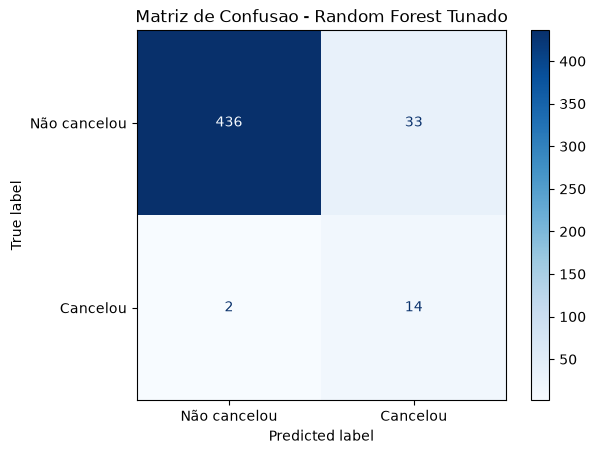

In [10]:
y_pred_rf = melhor_rf.predict(X_test)

print(f'Acuracia: {accuracy_score(y_test, y_pred_rf):.2%}')
print(f'Precisao (Sim): {precision_score(y_test, y_pred_rf, pos_label="Sim", zero_division=0):.2%}')
print(f'Recall (Sim): {recall_score(y_test, y_pred_rf, pos_label="Sim", zero_division=0):.2%}')
print(f'F1-score (Sim): {f1_score(y_test, y_pred_rf, pos_label="Sim", zero_division=0):.2%}')

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, cmap='Blues')
plt.title('Matriz de Confusao - Random Forest Tunado')
plt.show()
